# Exploratory analysis

This notebook compares the reported KSI rate across road, environmental, and time conditions. It pairs chi-square tests with Cramer's V because large samples can make small differences statistically significant.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "processed").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "collisions_clean.csv")

day_order = ["Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"]
period_order = ["Overnight", "Morning peak", "Daytime", "Evening peak", "Late evening"]
df["day_of_week"] = pd.Categorical(df["day_of_week"], categories=day_order, ordered=True)
df["time_of_day"] = pd.Categorical(df["time_of_day"], categories=period_order, ordered=True)

sns.set_theme(style="whitegrid", palette="muted")
FIGURE_DIR = PROJECT_ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

factors = [
    "speed_limit_band",
    "light",
    "weather",
    "road_surface",
    "urban_rural",
    "road_type",
    "junction_detail",
    "day_of_week",
    "time_of_day",
]

## Rates and association tests

Each rate is the observed share of collisions recorded as Fatal or Serious in that group. The chi-square test asks whether severity and factor are independent. Cramer's V summarizes association strength on a 0-to-1 scale; it is descriptive, not causal.

In [2]:
rate_tables = {}
test_rows = []

for factor in factors:
    grouped = df.groupby(factor, observed=True)["ksi"]
    rate_tables[factor] = grouped.agg(collisions="size", ksi_count="sum", ksi_rate="mean")

    table = pd.crosstab(df[factor], df["ksi"])
    test_table = table.copy()
    excluded_categories = []

    while test_table.shape[0] > 1:
        chi2, p_value, degrees_freedom, expected = chi2_contingency(
            test_table, correction=False
        )
        if expected.min() >= 5:
            break
        smallest_category = test_table.sum(axis=1).idxmin()
        excluded_categories.append(str(smallest_category))
        test_table = test_table.drop(index=smallest_category)

    chi2, p_value, degrees_freedom, expected = chi2_contingency(
        test_table, correction=False
    )
    sample_size = test_table.to_numpy().sum()
    dimension = min(test_table.shape[0] - 1, test_table.shape[1] - 1)
    cramers_v = (chi2 / (sample_size * dimension)) ** 0.5 if dimension > 0 else 0.0

    test_rows.append(
        {
            "factor": factor,
            "chi_square": chi2,
            "degrees_freedom": degrees_freedom,
            "p_value": p_value,
            "cramers_v": cramers_v,
            "minimum_expected_count": expected.min(),
            "excluded_rare_categories": "; ".join(excluded_categories) or "None",
        }
    )

association_results = pd.DataFrame(test_rows).sort_values("cramers_v", ascending=False)

for factor, table in rate_tables.items():
    print(f"\n{factor.replace('_', ' ').title()}")
    display(table.assign(ksi_rate_pct=table["ksi_rate"] * 100).round(2))

print("\nChi-square tests, ranked by Cramer's V")
association_display = association_results.copy()
association_display["p_value"] = association_display["p_value"].map(
    lambda value: "<0.001" if value < 0.001 else f"{value:.3g}"
)
display(association_display.round(4))


Speed Limit Band


,collisions,ksi_count,ksi_rate,ksi_rate_pct
speed_limit_band,,,,
20-30 mph,210975,47939,0.23,22.72
40 mph,26989,7192,0.27,26.65
50 mph,13883,3982,0.29,28.68
60 mph,38147,13360,0.35,35.02
70 mph,16713,4199,0.25,25.12
Unknown / missing,3,1,0.33,33.33



Light


,collisions,ksi_count,ksi_rate,ksi_rate_pct
light,,,,
"Darkness, lighting unknown",4902,1036,0.21,21.13
"Darkness, lights lit",63949,16525,0.26,25.84
"Darkness, no road lighting",19232,6635,0.34,34.50
Daylight,218605,52470,0.24,24.00
Unknown / missing,22,7,0.32,31.82



Weather


,collisions,ksi_count,ksi_rate,ksi_rate_pct
weather,,,,
Fine,247662,63419,0.26,25.61
Other,9447,1985,0.21,21.01
Rain,38628,9686,0.25,25.08
Snow or fog,2108,569,0.27,26.99
Unknown / missing,8865,1014,0.11,11.44


... (10 outputs left out)


Time Of Day


,collisions,ksi_count,ksi_rate,ksi_rate_pct
time_of_day,,,,
Overnight,17409,5399,0.31,31.01
Morning peak,51698,11529,0.22,22.30
Daytime,109182,26944,0.25,24.68
Evening peak,90644,22037,0.24,24.31
Late evening,37777,10764,0.28,28.49



Chi-square tests, ranked by Cramer's V


,factor,chi_square,degrees_freedom,p_value,cramers_v,minimum_expected_count,excluded_rare_categories
0,speed_limit_band,2766.9794,4,<0.001,0.0950,3470.5350,Unknown / missing
5,road_type,2273.1548,4,<0.001,0.0861,1924.3871,None
4,urban_rural,1939.9606,1,<0.001,0.0795,25479.8390,Unknown / missing; Unallocated
6,junction_detail,1248.7358,6,<0.001,0.0638,1201.6795,None
3,road_surface,1140.3680,3,<0.001,0.0610,1201.1795,None
1,light,1105.5132,4,<0.001,0.0600,5.4997,None
2,weather,1003.0105,4,<0.001,0.0572,526.9691,None
8,time_of_day,811.4455,4,<0.001,0.0514,4351.9946,None
7,day_of_week,369.0970,6,<0.001,0.0347,8570.4970,None


## Figures

Rates are shown with their group sizes in the tables above. The factor panel uses separate axes for readability; the hour and weekday plots keep the natural time order.

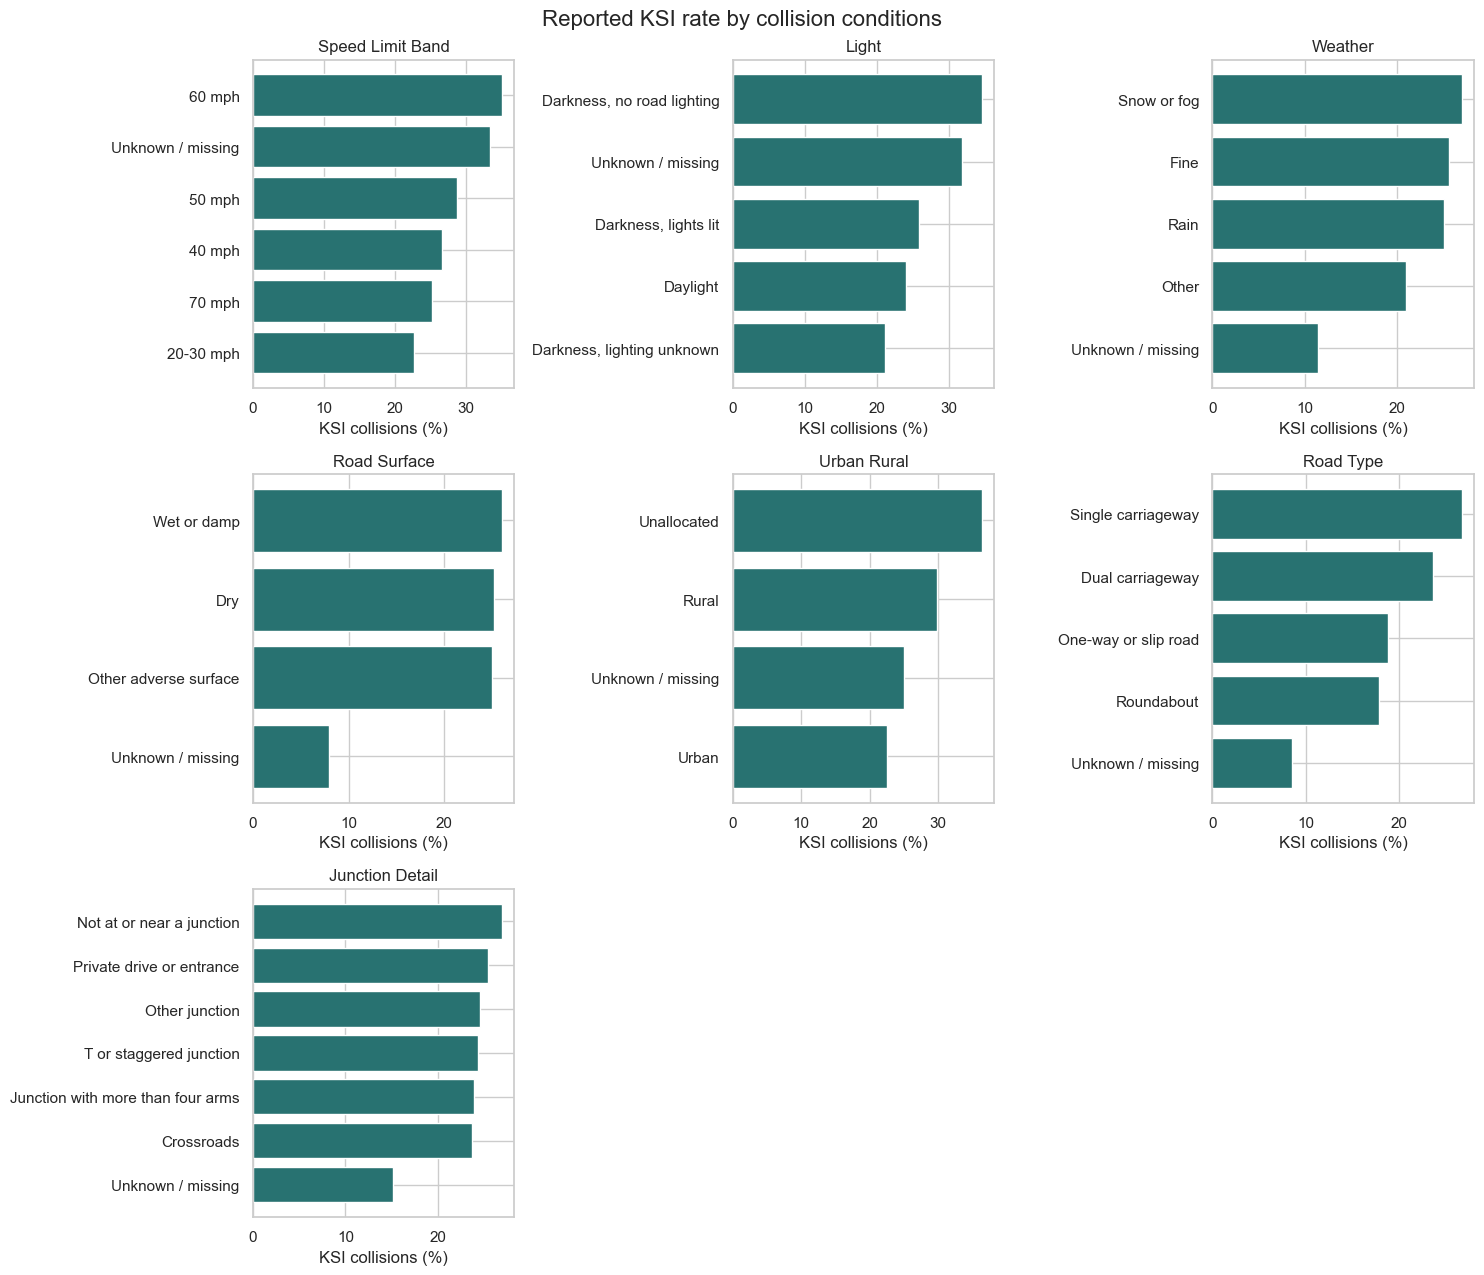

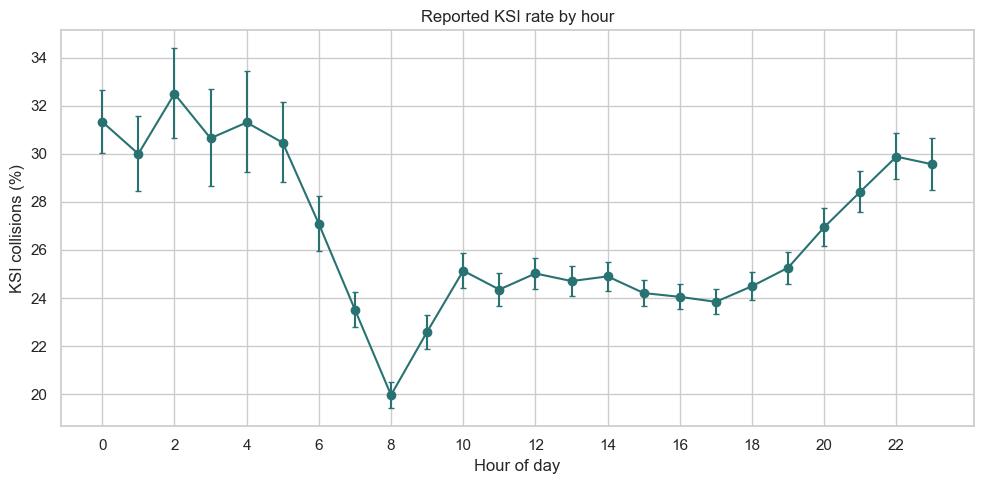

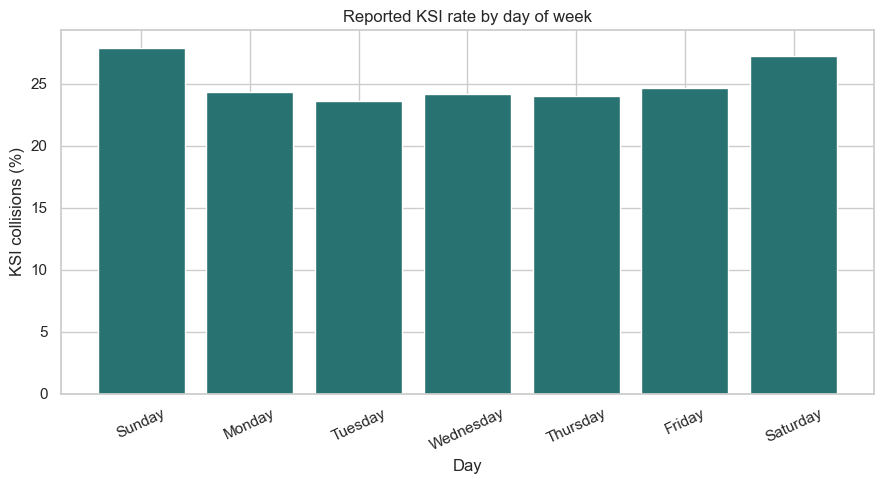

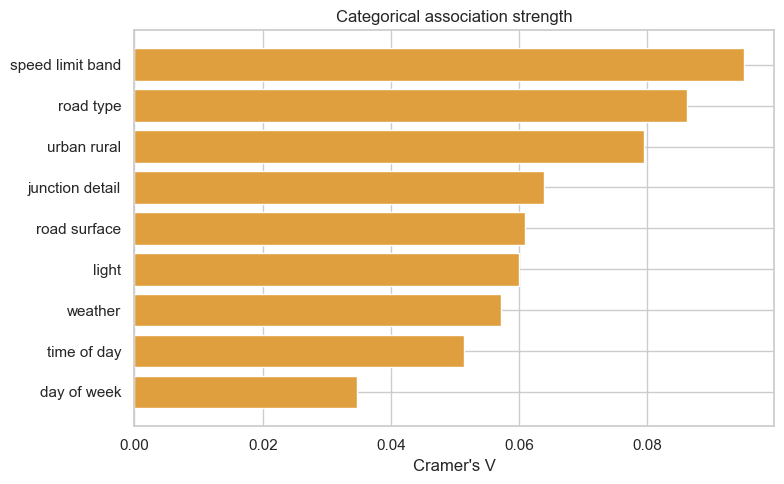

In [3]:
from statsmodels.stats.proportion import proportion_confint

plot_factors = [
    "speed_limit_band",
    "light",
    "weather",
    "road_surface",
    "urban_rural",
    "road_type",
    "junction_detail",
]
fig, axes = plt.subplots(3, 3, figsize=(15, 13))
for axis, factor in zip(axes.flat, plot_factors):
    plot_data = rate_tables[factor].sort_values("ksi_rate")
    axis.barh(plot_data.index.astype(str), plot_data["ksi_rate"] * 100, color="#287271")
    axis.set_title(factor.replace("_", " ").title())
    axis.set_xlabel("KSI collisions (%)")
    axis.set_ylabel("")
for axis in axes.flat[len(plot_factors):]:
    axis.set_visible(False)
fig.suptitle("Reported KSI rate by collision conditions", fontsize=16)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "ksi_rate_by_factor.png", dpi=200, bbox_inches="tight")
plt.show()

hourly = df.groupby("hour", observed=True)["ksi"].agg(collisions="size", ksi_count="sum")
hourly["ksi_rate"] = hourly["ksi_count"] / hourly["collisions"]
low, high = proportion_confint(hourly["ksi_count"], hourly["collisions"], method="wilson")
fig, axis = plt.subplots(figsize=(10, 5))
axis.errorbar(
    hourly.index,
    hourly["ksi_rate"] * 100,
    yerr=[(hourly["ksi_rate"] - low) * 100, (high - hourly["ksi_rate"]) * 100],
    fmt="o-",
    color="#287271",
    capsize=2,
)
axis.set(title="Reported KSI rate by hour", xlabel="Hour of day", ylabel="KSI collisions (%)")
axis.set_xticks(range(0, 24, 2))
fig.tight_layout()
fig.savefig(FIGURE_DIR / "ksi_rate_by_hour.png", dpi=200, bbox_inches="tight")
plt.show()

weekday = rate_tables["day_of_week"].reindex(day_order).dropna()
fig, axis = plt.subplots(figsize=(9, 5))
axis.bar(weekday.index.astype(str), weekday["ksi_rate"] * 100, color="#287271")
axis.set(title="Reported KSI rate by day of week", xlabel="Day", ylabel="KSI collisions (%)")
axis.tick_params(axis="x", rotation=25)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "ksi_rate_by_day.png", dpi=200, bbox_inches="tight")
plt.show()

fig, axis = plt.subplots(figsize=(8, 5))
ranked = association_results.sort_values("cramers_v")
axis.barh(ranked["factor"].str.replace("_", " "), ranked["cramers_v"], color="#e09f3e")
axis.set(title="Categorical association strength", xlabel="Cramer's V", ylabel="")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "cramers_v_by_factor.png", dpi=200, bbox_inches="tight")
plt.show()